# USA Housing

Năm cột số dùng để đoán:

- Avg. Area Income là thu nhập trung bình của khu vực
- Avg. Area House Age là tuổi nhà trung bình
- Avg. Area Number of Rooms là số phòng trung bình
- Avg. Area Number of Bedrooms là số phòng ngủ trung bình
- Area Population là dân số khu vực

Address là địa chỉ chữ. Cột này không đưa vào mô hình.


## 1. Đọc dữ liệu


In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("USA_Housing.csv")

df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386


## 2. Xem tổng quan

describe cho trung bình, giá trị nhỏ nhất và lớn nhất của các cột số. Giá trung bình khoảng 1,232,073.

columns in đủ 7 tên cột, kể cả Address.


In [9]:
df.describe()
df.columns.to_list()

['Avg. Area Income',
 'Avg. Area House Age',
 'Avg. Area Number of Rooms',
 'Avg. Area Number of Bedrooms',
 'Area Population',
 'Price',
 'Address']

## 3. Bỏ cột địa chỉ

Address là chữ, mỗi căn một địa chỉ khác nhau. Linear Regression cần cột số. Bỏ Address trước khi tách feature.


In [43]:
# df = ?
df = df.drop("Address", axis=1)



In [21]:
df.columns.to_list()

['Avg. Area Income',
 'Avg. Area House Age',
 'Avg. Area Number of Rooms',
 'Avg. Area Number of Bedrooms',
 'Area Population',
 'Price']

In [22]:
df

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05
...,...,...,...,...,...,...
4995,60567.94414,7.830362,6.137356,3.46,22837.36103,1.060194e+06
4996,78491.27543,6.999135,6.576763,4.02,25616.11549,1.482618e+06
4997,63390.68689,7.250591,4.805081,2.13,33266.14549,1.030730e+06
4998,68001.33124,5.534388,7.130144,5.44,42625.62016,1.198657e+06


## 4. Thu nhập khu vực và giá

Biểu đồ này đặt Avg. Area Income trên trục ngang và Price trên trục dọc. Khu có thu nhập cao hơn thường có giá nhà cao hơn. Đám điểm đi theo một hướng, chưa thành một đường thẳng duy nhất vì giá còn phụ thuộc tuổi nhà, số phòng và dân số.


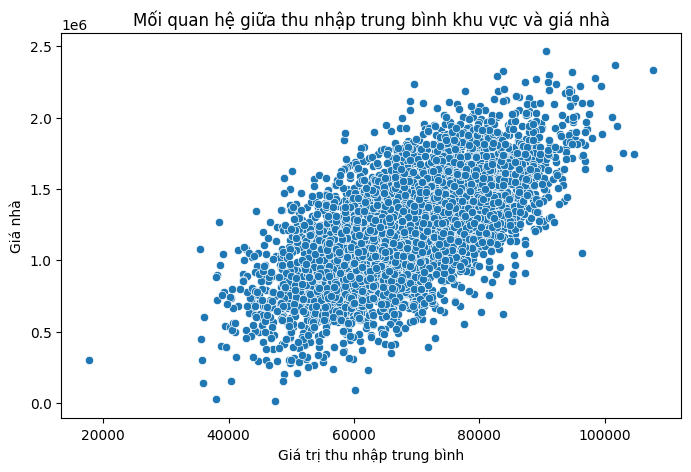

In [24]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Avg. Area Income",
    y="Price"
)
plt.title("Mối quan hệ giữa thu nhập trung bình khu vực và giá nhà")
plt.xlabel("Giá trị thu nhập trung bình")
plt.ylabel("Giá nhà")
plt.show()

## 5. Tách feature, label, rồi chia tập



In [44]:
# Tách 5 cột đầu vào (features) khỏi cột giá nhà cần dự đoán (label).
x = df.drop(columns="Price")
y = df["Price"]

# Chia dữ liệu: 80% để huấn luyện, 20% để kiểm tra.
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Kiểm tra số dòng đã được chia vào mỗi tập.
print("Số dòng train:", len(x_train))
print("Số dòng test:", len(x_test))

Số dòng train: 4000
Số dòng test: 1000


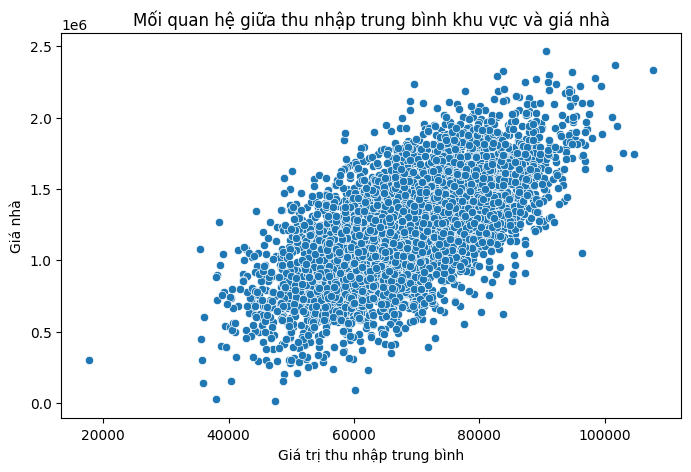

In [27]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Avg. Area Income",
    y="Price"
)
plt.title("Mối quan hệ giữa thu nhập trung bình khu vực và giá nhà")
plt.xlabel("Giá trị thu nhập trung bình")
plt.ylabel("Giá nhà")
plt.show()

## 6. Training

$$\hat{y} = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5 + b$$

Năm weight nằm trong coef_. b là intercept_.


| Ký hiệu   | Ý nghĩa                        |
| --------- | ------------------------------ |
| `ŷ`       | Giá nhà mô hình dự đoán        |
| `x₁`      | `Avg. Area Income`             |
| `x₂`      | `Avg. Area House Age`          |
| `x₃`      | `Avg. Area Number of Rooms`    |
| `x₄`      | `Avg. Area Number of Bedrooms` |
| `x₅`      | `Area Population`              |
| `w₁...w₅` | Trọng số của 5 feature         |
| `b`       | Bias/intercept                 |


In [45]:
#Khởi tạo mô hình linear regression
model = LinearRegression()
#Traning mô hình bằng dữ liệu train
model.fit(x_train, y_train)

LinearRegression()

In [32]:
print("Weights: ", model.coef_.tolist())

Weights:  [21.271898335993644, 169485.8369678995, 124869.34771098614, -1402.9440943784514, 14.900648327748058]


In [46]:
# Dự đoán giá nhà cho tập test.
y_pred = model.predict(x_test)

# MSE đo sai số bình phương trung bình; RMSE đổi sai số về đơn vị giá nhà.
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# R2 cho biết mô hình giải thích được bao nhiêu biến thiên của giá.
r2 = r2_score(y_test, y_pred)

print("MSE =", f"{mse:,.0f}")
print("RMSE =", f"{rmse:,.0f}")
print("R2 =", round(r2, 3))

MSE = 10,089,009,299
RMSE = 100,444
R2 = 0.918


In [34]:
#Dự đoán gái nhà trên test
y_pred = model.predict(x_test)
#Đo mức độ sai lệch của giá thực tế và giá dự đoán
mse = mean_squared_error(y_test, y_pred)
#Xem phần trăm biến thiên của Price
r2 = r2_score(y_test, y_pred)
#Căn bật 2 của mức độ sai lệch
rmse = np.sqrt(mse)
print("MSE(độ sai lệch của giá thực tế và giá dự đoán) =", f"{mse:,.0f}")
print("RMSE(căn bật hai của độ sai lệch của giá thực tế và giá dự đoán) =", f"{rmse:,.0f}")
print("R2 =", round(r2, 3))


MSE(độ sai lệch của giá thực tế và giá dự đoán) = 10,336,347,321
RMSE(căn bật hai của độ sai lệch của giá thực tế và giá dự đoán) = 101,668
R2 = 0.917


## 8. Một căn trong tập kiểm tra

Căn đầu tiên của tập kiểm tra không nằm trong tập học. In giá thật cạnh giá đoán. Hai số có dấu phẩy để dễ đọc.

Nếu giá đoán gần giá thật và khoảng lệch nhỏ hơn RMSE, căn đó nằm trong mức sai số trung bình của mô hình.


In [47]:
# Chọn căn đầu tiên trong tập test; căn này chưa được dùng để huấn luyện.
can = x_test.iloc[[0]]

# Lấy giá thật và giá mô hình dự đoán cho căn đó.
gia_that = y_test.iloc[0]
gia_doan = model.predict(can)[0]

print(can)
print("Giá thật =", f"{gia_that:,.0f}")
print("Giá dự đoán =", f"{gia_doan:,.0f}")

      Avg. Area Income  Avg. Area House Age  Avg. Area Number of Rooms  \
1501       61907.59335             7.017838                   6.440256   

      Avg. Area Number of Bedrooms  Area Population  
1501                          3.25      43828.94721  
Giá thật = 1,339,096
Giá dự đoán = 1,308,588


In [38]:
can = x_test.iloc[[0]]
gia_that = y_test.iloc[0]
gia_doan = y_pred[0]
print(can)
print("Real price =", f"{gia_that:,.0f}")
print("Predicted price =", f"{gia_doan:,.0f}")

      Avg. Area Income  Avg. Area House Age  Avg. Area Number of Rooms  \
4227       66547.01645             5.846095                   6.847298   

      Avg. Area Number of Bedrooms  Area Population  
4227                          4.13       27850.8229  
Real price = 1,094,880
Predicted price = 1,025,037


## 9. Save model

joblib.dump ghi weight và bias ra USA_Housing.pkl. joblib.load đọc lại khi cần đoán, không cần fit lại.

Khu thử dùng năm số tròn để dễ nhìn: thu nhập 70,000, tuổi nhà 6, 7 phòng, 4 phòng ngủ, dân số 40,000.


In [39]:
import joblib

# Lưu mô hình đã train
joblib.dump(model, "USA_Housing.pkl")

print("Đã lưu model vào file USA_Housing.pkl")

Đã lưu model vào file USA_Housing.pkl


In [40]:
# Đọc lại model từ file
model_loaded = joblib.load("USA_Housing.pkl")

print("Đã load model thành công!")

Đã load model thành công!


In [41]:
# Dữ liệu của một căn nhà mới
can_moi = np.array([[70000, 6, 7, 4, 40000]])
                #thu nhập,tuổinhà,sốphòng, số phòng ngủ, dân số
# Dự đoán giá nhà
gia_du_doan = model_loaded.predict(can_moi)

print("Predicted price =", f"{gia_du_doan[0]:,.0f}")

Predicted price = 1,324,854


c:\Users\Tra Quoc Huy\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
